### В данной лабораторной работе изучаются следующие методы решения задач условной оптимизации:
1. метод штрафных функций
2. метод барьерных функций
3. метод проекции градиента
4. метод условного градиента

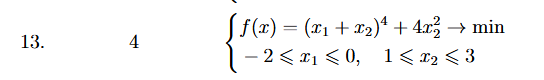

Вариант 13

In [ ]:
import numpy as np
import sympy as sp
import pandas as pd
import plotly.graph_objects as go
import random 


def auxiliary_point(grad, lower, upper, step=0.1, maxiter=500, eps=1e-5):
    x = np.array([(lower[0] + upper[0]) / 2, (lower[1] + upper[1]) / 2])
    for _ in range(maxiter):
        c_grad = np.array([grad[0](x[0], x[1]), grad[1](x[0], x[1])])
        x_new = x - step * c_grad   # шаг градиентного спуска
        x_new = np.clip(x_new, lower, upper)  # проекция на параллелепипед
        if np.linalg.norm(x_new - x) < eps:
            break
        x = x_new
    return x

def select_alpha_gd(f_sym, grad, x, p, alpha=0.5, step_size=0.1, maxiter=100, eps=1e-5):
    # Преобразуем f_sym в числовую функцию (аналогично auxiliary_point)
    f_num = sp.lambdify([x1, x2], f_sym, "math")
    
    for _ in range(maxiter):
        x_alpha = x + alpha * p
        # Вычисляем градиент в x_alpha через grad
        g = np.array([grad[0](x_alpha[0], x_alpha[1]),
                      grad[1](x_alpha[0], x_alpha[1])])
        grad_phi = np.dot(g, p)   # производная phi'(alpha)
        alpha_new = alpha - step_size * grad_phi
        alpha_new = np.clip(alpha_new, 0.0, 1.0)
        if np.linalg.norm(alpha_new - alpha) < eps:
            break
        alpha = alpha_new
    return alpha

def cond_grad(f, x0, lower, upper, eps = 1e-5, maxiter = 5000):
    x = x0.copy()
    
    if not lower[0]<= x[0] <= upper[0] and lower[1] <= x[1] <= upper[1]:
        return "Point is out of bounds"
    fun = sp.lambdify([x1, x2], f, "math")
    x_path = [x.copy()]
    fx = fun(x[0], x[1])
    f_path = [fx]

    x1d = sp.diff(f, x1)
    x2d = sp.diff(f, x2)
    x1d = sp.lambdify([x1, x2], x1d, "math")
    x2d = sp.lambdify([x1, x2], x2d, "math")

    for k in range(maxiter):
        c_grad = np.array([x1d(x[0], x[1]), x2d(x[0], x[1])])

        x_bar = auxiliary_point([x1d, x2d], lower, upper)
        direction = x_bar - x
        if np.linalg.norm(direction) < eps:
            break

        alpha = select_alpha_gd(f, [x1d, x2d], x, direction, step_size=0.05, maxiter=50)

        x = x + alpha * direction
        x_path.append(x.copy())
        fx = fun(x[0], x[1])
        f_path.append(fx)

        if np.linalg.norm(alpha * direction) < eps:
            break

    return x_path, f_path, k+1


x1, x2 = sp.symbols('x1, x2')
f = (x1+x2)**4 + 4*x2**2
np.random.seed(42)
p_list = ([3, 3], [random.uniform(-2, 0), random.uniform(1, 3)], [random.uniform(-2, 0),  random.uniform(1, 3)])
e_list = (0.1, 1e-6)
lower = [-2, 1]
upper = [0, 3]
x1_range = np.linspace(-3, 1, 100)
x2_range = np.linspace(0, 4, 100)

x, y = np.meshgrid(x1_range, x2_range)
fu = (x+y)**4 + 4*y**2
fig = go.Figure(data=[go.Contour(
    zmax = 5000, zmin = 0,
    z=fu, x=x1_range, y=x2_range, colorscale='Jet',
    contours=dict(
         coloring = 'lines',
        showlabels = True,
        labelfont = dict(
            size = 12,
            color = 'white',
        )
    ) 
)])
fig.update_layout(title=f'(x1+x2)^4 + 4*x2^2') 
fig.add_shape(type="rect",
    x0=-2, y0=1, x1=0, y1=3,
    line=dict(color="RoyalBlue"),)

# method visualize

for point in p_list:
    for e in e_list:
        print(f'point = {point}')
        ans = cond_grad(f, point, lower, upper, eps=e)
        if isinstance(ans, str):
            print(ans)
            continue
        print(ans[0], ans[1], ans[2])
        fig.add_trace(go.Scatter(x=[i[0] for i in ans[0]], y=[i[1] for i in ans[0]], name=f'точка {point}'))
fig.show()

point = [3, 3]
Point is out of bounds
point = [3, 3]
Point is out of bounds
point = [-1.6032395987239796, 2.138296141850489]
[[-1.6032395987239796, 2.138296141850489], array([-1.04950792,  1.        ])] [18.37120095100738, np.float64(4.000006007566387)] 2
point = [-1.6032395987239796, 2.138296141850489]
[[-1.6032395987239796, 2.138296141850489], array([-1.04950792,  1.        ])] [18.37120095100738, np.float64(4.000006007566387)] 2
point = [-1.9834012398744318, 2.3517660605039277]
[[-1.9834012398744318, 2.3517660605039277], array([-1.04950792,  1.        ])] [22.141626906195217, np.float64(4.000006007566387)] 2
point = [-1.9834012398744318, 2.3517660605039277]
[[-1.9834012398744318, 2.3517660605039277], array([-1.04950792,  1.        ])] [22.141626906195217, np.float64(4.000006007566387)] 2
